In [126]:
import pandas as pd
import matplotlib.pyplot as plt

In [127]:
data = pd.read_csv("final_results.csv")

In [128]:
data

,same_machine,artificial_delay,total_server_threads,avg_time,requests_per_client,total_clients
0,0,0,1,1.175716e+05,10,1
1,0,0,1,1.231805e+06,100,1
2,0,0,1,1.327405e+07,1000,1
3,0,1,1,7.302631e+05,10,1
4,0,1,1,7.750736e+06,100,1
5,0,1,1,7.211065e+07,1000,1
6,1,0,1,2.054130e+04,10,1
7,1,0,1,1.898087e+05,100,1
8,1,0,1,1.864489e+06,1000,1
9,1,1,1,4.770408e+05,10,1


* We are first interested into testing how our Rudy handles requests coming from the same machine 

In [129]:
same_machine_data = data[(data["same_machine"] == 1) & (data["total_server_threads"] == 1)]
same_machine_data

,same_machine,artificial_delay,total_server_threads,avg_time,requests_per_client,total_clients
6,1,0,1,20541.3,10,1
7,1,0,1,189808.7,100,1
8,1,0,1,1864488.9,1000,1
9,1,1,1,477040.8,10,1
10,1,1,1,4707922.0,100,1
11,1,1,1,47168553.2,1000,1


* With this table, we can compute the requests per second for each batch

In [130]:
same_machine_data["req/second"] = same_machine_data["requests_per_client"] / (same_machine_data["avg_time"] / 1_000_000)

C:\Users\ilias\AppData\Local\Temp\ipykernel_22748\2277930271.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  same_machine_data["req/second"] = same_machine_data["requests_per_client"] / (same_machine_data["avg_time"] / 1_000_000)


* Lets see how the requests per second rate behaves, depending the existence of an artificial server-side delay 

In [131]:
same_machine_data[same_machine_data["artificial_delay"] == 1]

,same_machine,artificial_delay,total_server_threads,avg_time,requests_per_client,total_clients,req/second
9,1,1,1,477040.8,10,1,20.962568
10,1,1,1,4707922.0,100,1,21.240794
11,1,1,1,47168553.2,1000,1,21.200565


In [132]:
same_machine_data[same_machine_data["artificial_delay"] == 0]

,same_machine,artificial_delay,total_server_threads,avg_time,requests_per_client,total_clients,req/second
6,1,0,1,20541.3,10,1,486.824106
7,1,0,1,189808.7,100,1,526.846240
8,1,0,1,1864488.9,1000,1,536.340013


* As expected:
    1. when a server-side delay is included in every request, the request times increase and the req/second metric decreases
    2. the requests per second rate stays pretty consistent, irregardless of the number of requests performed

* At the same time, we notice slightly more fluctuating `req/second` values when we remove the server-side delay

* This indicates that the delay manages to "hide" any other small overhead that affected the request times, because it overtakes them

* The fact that the `req/second` rate also plummets when the delay is present (from [486, 536] to [20, 21]), also supports the above statement

* Lets continue with a sanity check, and examine what happens visually, when the total number of requests increases

* First, with an artificial delay of 40 milliseconds

In [133]:
same_machine_with_delay = same_machine_data[same_machine_data["artificial_delay"] == 1][["requests_per_client", "avg_time", "req/second"]]
same_machine_with_delay

,requests_per_client,avg_time,req/second
9,10,477040.8,20.962568
10,100,4707922.0,21.240794
11,1000,47168553.2,21.200565


<Axes: title={'center': 'Average Time for Each Total Requests Value (same machine, artificial_delay=40milliseconds)'}, xlabel='Total Requests', ylabel='Average Time (microseconds)'>

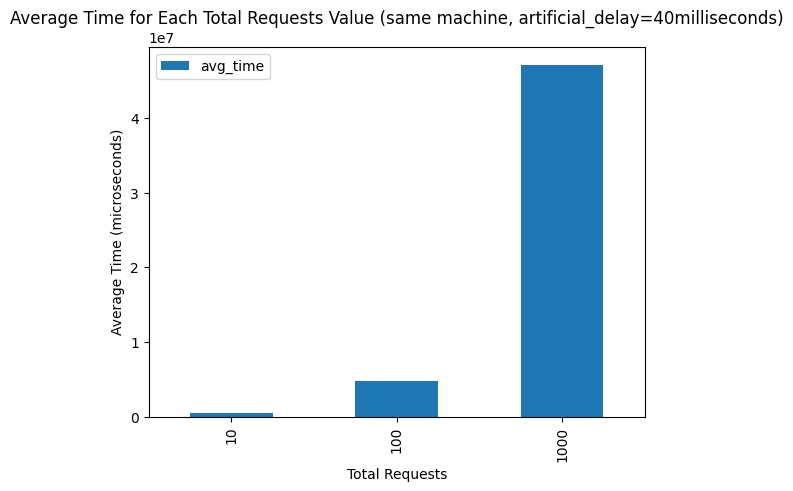

In [134]:
same_machine_with_delay.plot(kind='bar', x='requests_per_client', y='avg_time', title='Average Time for Each Total Requests Value (same machine, artificial_delay=40milliseconds)', xlabel='Total Requests', ylabel='Average Time (microseconds)')

* And now without the artificial delay

In [135]:
same_machine_no_delay = same_machine_data[same_machine_data["artificial_delay"] == 0][["requests_per_client", "avg_time", "req/second"]]
same_machine_no_delay

,requests_per_client,avg_time,req/second
6,10,20541.3,486.824106
7,100,189808.7,526.846240
8,1000,1864488.9,536.340013


<Axes: title={'center': 'Average Time for Each Total Requests Value (same machine, no artificial delay)'}, xlabel='Total Requests', ylabel='Average Time (microseconds)'>

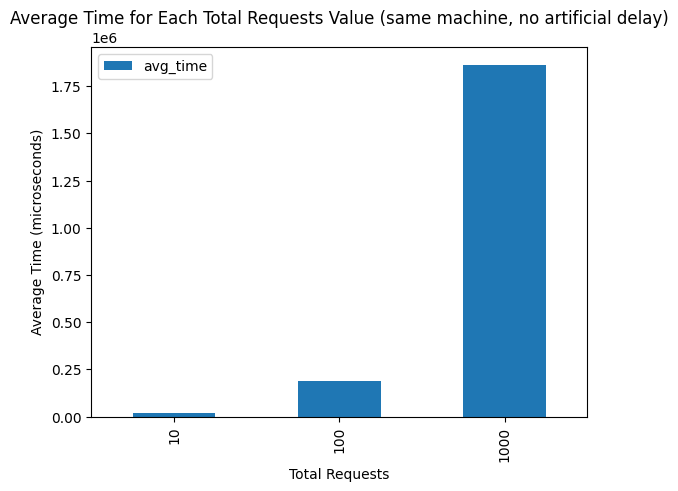

In [136]:
same_machine_no_delay.plot(kind='bar', x='requests_per_client', y='avg_time', title='Average Time for Each Total Requests Value (same machine, no artificial delay)', xlabel='Total Requests', ylabel='Average Time (microseconds)')

* As expected, when we emit the artificial delay, the average request times decreases

* Lets see the times side-by-side

In [137]:
delay_no_delay_comparison = same_machine_with_delay.merge(same_machine_no_delay, on="requests_per_client", suffixes=("_with_delay", "_no_delay"))#.plot(kind='bar', title='Average Time for Each Total Requests Value (same machine, with and without artificial delay)', xlabel='Total Requests', ylabel='Average Time (microseconds)')
delay_no_delay_comparison["time_diff"] = delay_no_delay_comparison["avg_time_with_delay"] - delay_no_delay_comparison["avg_time_no_delay"]
delay_no_delay_comparison["time_diff_per"] = delay_no_delay_comparison["avg_time_with_delay"] / delay_no_delay_comparison["avg_time_no_delay"]
delay_no_delay_comparison["rate_diff"] = delay_no_delay_comparison["req/second_with_delay"] - delay_no_delay_comparison["req/second_no_delay"]
delay_no_delay_comparison["rate_diff_per"] = delay_no_delay_comparison["req/second_with_delay"] / delay_no_delay_comparison["req/second_no_delay"]
delay_no_delay_comparison

,requests_per_client,avg_time_with_delay,req/second_with_delay,avg_time_no_delay,req/second_no_delay,time_diff,time_diff_per,rate_diff,rate_diff_per
0,10,477040.8,20.962568,20541.3,486.824106,456499.5,23.223496,-465.861538,0.043060
1,100,4707922.0,21.240794,189808.7,526.846240,4518113.3,24.803510,-505.605447,0.040317
2,1000,47168553.2,21.200565,1864488.9,536.340013,45304064.3,25.298382,-515.139447,0.039528


* The delay seems to have a non-fluctuating effect on the request times, even when the request amounts increase drastically (the range is [23, 25])

## Multiple Machines

* Lets see what happens when we repeat the same experiments, but with a different machine doing the requests 

In [138]:
different_machine_data = data[(data["same_machine"] == 0) & (data["total_server_threads"] == 1)]
different_machine_data["req/second"] = different_machine_data["requests_per_client"] / (different_machine_data["avg_time"] / 1_000_000)
different_machine_data

C:\Users\ilias\AppData\Local\Temp\ipykernel_22748\227371724.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  different_machine_data["req/second"] = different_machine_data["requests_per_client"] / (different_machine_data["avg_time"] / 1_000_000)


,same_machine,artificial_delay,total_server_threads,avg_time,requests_per_client,total_clients,req/second
0,0,0,1,117571.6,10,1,85.054554
1,0,0,1,1231805.2,100,1,81.181667
2,0,0,1,13274045.8,1000,1,75.334982
3,0,1,1,730263.1,10,1,13.693695
4,0,1,1,7750735.8,100,1,12.902001
5,0,1,1,72110652.2,1000,1,13.867577


* Lets compare the average request times by the same and different machine, side by side

* First, lets split the data with and without our artificial delay once again

In [139]:
different_machine_data_with_delay = different_machine_data[different_machine_data["artificial_delay"] == 1][["requests_per_client", "avg_time", "req/second"]]
different_machine_data_with_delay

,requests_per_client,avg_time,req/second
3,10,730263.1,13.693695
4,100,7750735.8,12.902001
5,1000,72110652.2,13.867577


In [140]:
different_machine_data_no_delay = different_machine_data[different_machine_data["artificial_delay"] == 0][["requests_per_client", "avg_time", "req/second"]]
different_machine_data_no_delay

,requests_per_client,avg_time,req/second
0,10,117571.6,85.054554
1,100,1231805.2,81.181667
2,1000,13274045.8,75.334982


* And compute the time differences

In [141]:
with_delay = same_machine_with_delay.merge(different_machine_data_with_delay, on="requests_per_client", suffixes=("_same_machine", "_different_machine"))
with_delay["time_diff"] = with_delay["avg_time_different_machine"] - with_delay["avg_time_same_machine"]
with_delay["time_diff_per"] = with_delay["avg_time_different_machine"] / with_delay["avg_time_same_machine"]
with_delay["rate_diff"] = with_delay["req/second_different_machine"] - with_delay["req/second_same_machine"]
with_delay["rate_diff_per"] = with_delay["req/second_different_machine"] / with_delay["req/second_same_machine"]
with_delay

,requests_per_client,avg_time_same_machine,req/second_same_machine,avg_time_different_machine,req/second_different_machine,time_diff,time_diff_per,rate_diff,rate_diff_per
0,10,477040.8,20.962568,730263.1,13.693695,253222.3,1.530819,-7.268873,0.653245
1,100,4707922.0,21.240794,7750735.8,12.902001,3042813.8,1.646318,-8.338793,0.607416
2,1000,47168553.2,21.200565,72110652.2,13.867577,24942099.0,1.528787,-7.332989,0.654114


* As we can see, when executing the requests from a different machine, the requests require greater times to be completed (about 1.5% more)

* This can easily be attributed to the fact that we have an extra network overhead since each request is required to travel in the local area network (LAN) to reach our server, instead of staying in the same operating system (by executing on the same machine)

* We should expect similar results even without having an artificial delay server-side

In [142]:
no_delay = same_machine_no_delay.merge(different_machine_data_no_delay, on="requests_per_client", suffixes=("_same_machine", "_different_machine"))
no_delay["time_diff"] = no_delay["avg_time_different_machine"] - no_delay["avg_time_same_machine"]
no_delay["time_diff_per"] = no_delay["avg_time_different_machine"] / no_delay["avg_time_same_machine"]
no_delay["rate_diff"] = no_delay["req/second_different_machine"] - no_delay["req/second_same_machine"]
no_delay["rate_diff_per"] = no_delay["req/second_different_machine"] / no_delay["req/second_same_machine"]

no_delay

,requests_per_client,avg_time_same_machine,req/second_same_machine,avg_time_different_machine,req/second_different_machine,time_diff,time_diff_per,rate_diff,rate_diff_per
0,10,20541.3,486.824106,117571.6,85.054554,97030.3,5.723669,-401.769552,0.174713
1,100,189808.7,526.846240,1231805.2,81.181667,1041996.5,6.489719,-445.664573,0.154090
2,1000,1864488.9,536.340013,13274045.8,75.334982,11409556.9,7.119402,-461.005031,0.140461


* This is interesting. This time, the difference is quite more significant

* From an average of 1.5, we jumped to a 5, 6 and 7 times increase in average request time 

* This once again gives us an indication that the artificial delay is <b>so significant</b>, that it even manages to hide the overhead that was created by sending the requests by a different machine

## Multiple Threads

* Up to this point, we have have only examined the case of a single-threaded server

* This means that our server was able to handle only one request at a time, finish, and then work on the next request

* It would be useful to see what changes when we increase the number of threads (meaning the number of requests that can be handled simultaneously) of our Rudy

* In order to not increase the length of this analysis (and overcomplicate it without reason), will we first fix some of the variables of the experiment

* Firstly, it makes sense to test a multi-threaded server, only when there is a server-side processing delay

* Because, if no delay exists server-side, and each response gets sent back fast, the same thread can then be used for the next request, without a large overhead

* Instead, if each request requires some server-processing, that is when a multi-threaded server shines the most. Since a request reaching the server when the server is busy processing a different request, can still be handled by a different thread

* Secondly, instead of comparing cases with multiple rounds of requests (e.g. 10, 100 and 1000 request), lets fix that as well to 100 requests

* But we have to remember something. Our case of interest right now, is when Rudy receives a new request, before having completed the previous one

* We cant simulate this behaviour with only one client process (since the client waits for the server to be done before sending the next request)

* This means that Rudy should be hit by multiple clients at the same time (*oh no*)

* Lets start with the case of a single machine again (all clients exist in the same machine as Rudy)

In [143]:
multiple_server_threads_data = data[(data["same_machine"] == 1) & (data["total_server_threads"] > 1)]
multiple_server_threads_data["req/second"] = (multiple_server_threads_data["requests_per_client"] * multiple_server_threads_data["total_clients"]) / (multiple_server_threads_data["avg_time"] / 1_000_000)
multiple_server_threads_data

C:\Users\ilias\AppData\Local\Temp\ipykernel_22748\364395057.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  multiple_server_threads_data["req/second"] = (multiple_server_threads_data["requests_per_client"] * multiple_server_threads_data["total_clients"]) / (multiple_server_threads_data["avg_time"] / 1_000_000)


,same_machine,artificial_delay,total_server_threads,avg_time,requests_per_client,total_clients,req/second
12,1,1,4,4744910.700,100,2,42.150424
13,1,1,4,4833308.250,100,4,82.759050
14,1,1,4,7066947.900,100,6,84.902282
15,1,1,6,4742813.125,100,4,84.338132
16,1,1,6,4745018.900,100,6,126.448390
17,1,1,6,6282988.725,100,8,127.327938
18,1,1,8,4910567.400,100,6,122.185473
19,1,1,8,4949041.600,100,8,161.647459
20,1,1,8,5961453.720,100,10,167.744320


* As is evident from the table, the tested cases are the following:
    * server-threads:
        * 4:
            * concurrent clients:
                * 2
                * 4
                * 6
        * 6
            * concurrent clients:
                * 4
                * 6
                * 8
        * 8
            * concurrent clients:
                * 6
                * 8
                * 10

* So we increase the number of threads in parallel with the number of clients

* Each concurrent client makes a total of 100 requests, 10 times (as all numbers are taken as averages of 10), before terminating

* The `avg_time` column is then computed by taking the average of all clients

* So, `avg_time` is a measure of the average time each client required to complete 100 requests

* Lets compare these times with the single-threaded ones

In [144]:
multiple_server_threads_data[["total_clients", "total_server_threads", "avg_time", "req/second"]]

,total_clients,total_server_threads,avg_time,req/second
12,2,4,4744910.700,42.150424
13,4,4,4833308.250,82.759050
14,6,4,7066947.900,84.902282
15,4,6,4742813.125,84.338132
16,6,6,4745018.900,126.448390
17,8,6,6282988.725,127.327938
18,6,8,4910567.400,122.185473
19,8,8,4949041.600,161.647459
20,10,8,5961453.720,167.744320


In [145]:
single_client_single_thread = same_machine_data[(same_machine_data["artificial_delay"] == 1) & (same_machine_data["requests_per_client"] == 100)]
single_client_single_thread

,same_machine,artificial_delay,total_server_threads,avg_time,requests_per_client,total_clients,req/second
10,1,1,1,4707922.0,100,1,21.240794


* As we can see from the first two rows of the `multiple_server_threads_data` table, even when we have 2 or 4 concurrent clients hammering the server at the same time, if we have at least as many server-threads (meaning server threads >= clients), the average request time reported is the same as if we had 1 client on a single-threaded server

* This suggests that each client managed to get satisfied by a different thread, and thus we didn't have any bottlenecks (meaning a client waiting to get served for long periods)

* The same holds true for the other cases of the table as well:
    * 4 or 6 clients on 6 threads
    * 6 or 8 clients on 8 threads

* The story is not the same when we have more concurrent clients than server threads, though

* Lets take a look at the following cases:

In [146]:
more_clients_than_threads = multiple_server_threads_data[["total_clients", "total_server_threads", "avg_time"]].iloc[[2, 5, 8]]
more_clients_than_threads

,total_clients,total_server_threads,avg_time
14,6,4,7066947.900
17,8,6,6282988.725
20,10,8,5961453.720


In [147]:
more_clients_than_threads["diff"] = more_clients_than_threads["avg_time"].values - single_client_single_thread["avg_time"].values
more_clients_than_threads["diff_per"] = more_clients_than_threads["avg_time"].values / single_client_single_thread["avg_time"].values
more_clients_than_threads

,total_clients,total_server_threads,avg_time,diff,diff_per
14,6,4,7066947.900,2359025.900,1.501076
17,8,6,6282988.725,1575066.725,1.334557
20,10,8,5961453.720,1253531.720,1.266260


* These cases prove that by having more concurrent clients than available server-threads, the average request times increase, since now some clients will have to wait for a server-thread to become available

In [148]:
more_clients_than_threads["diff_per"].mean()

np.float64(1.3672975285062072)

* More precisely, when the number of concurrent clients is 2 more than the available threads, the average request time is \~1.4 times larger (microseconds)

* Even though we currently don't have enough data to make a concrete statement, it also appears that as the number of clients and threads increase by a common number, the difference in the request times appear to become less significant (from 1.5 to 1.3 and then 1.2)

* This may be an indicator that in a production server of hundred of threads, the clients will probably not experience any serious bottlenecks, even if the system is handling thousand of users at the same time

## Multiple Threads on Different Machine

* Now, lets see what happens when we have multiple concurrent client processes running on a different machine  

In [153]:
multiple_threads_different_machines = data[(data["same_machine"] == 0) & (data["total_server_threads"] > 1)]
multiple_threads_different_machines["req/second"] = (multiple_threads_different_machines["requests_per_client"] * multiple_threads_different_machines["total_clients"]) / (multiple_threads_different_machines["avg_time"] / 1_000_000)
multiple_threads_different_machines

C:\Users\ilias\AppData\Local\Temp\ipykernel_22748\4257808388.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  multiple_threads_different_machines["req/second"] = (multiple_threads_different_machines["requests_per_client"] * multiple_threads_different_machines["total_clients"]) / (multiple_threads_different_machines["avg_time"] / 1_000_000)


,same_machine,artificial_delay,total_server_threads,avg_time,requests_per_client,total_clients,req/second
21,0,1,4,6506423.400,100,2,30.738854
22,0,1,4,7663298.775,100,4,52.196843
23,0,1,4,7620268.350,100,6,78.737385
24,0,1,6,7388130.000,100,4,54.140899
25,0,1,6,7369110.800,100,6,81.420950
26,0,1,6,7875873.425,100,8,101.576036
27,0,1,8,7873652.300,100,6,76.203517
28,0,1,8,6913271.100,100,8,115.719460
29,0,1,8,6352645.000,100,10,157.414746


* And compare these with the same-machine ones

In [155]:
multiple_threads_comparison = multiple_server_threads_data.merge(
    multiple_threads_different_machines,
    on=["total_server_threads", "total_clients"],
    suffixes=("_same_machine", "_different_machine")
)[["total_clients", "total_server_threads", "avg_time_same_machine", "avg_time_different_machine", "req/second_same_machine", "req/second_different_machine"]]

multiple_threads_comparison["time_diff"] = (
    multiple_threads_comparison["avg_time_different_machine"]
    - multiple_threads_comparison["avg_time_same_machine"]
)

multiple_threads_comparison["time_diff_per"] = (
    multiple_threads_comparison["avg_time_different_machine"]
    / multiple_threads_comparison["avg_time_same_machine"]
)

multiple_threads_comparison["rate_diff"] = (
    multiple_threads_comparison["req/second_different_machine"]
    - multiple_threads_comparison["req/second_same_machine"]
)

multiple_threads_comparison["rate_diff_per"] = (
    multiple_threads_comparison["req/second_different_machine"]
    / multiple_threads_comparison["req/second_same_machine"]
)

multiple_threads_comparison

,total_clients,total_server_threads,avg_time_same_machine,avg_time_different_machine,req/second_same_machine,req/second_different_machine,time_diff,time_diff_per,rate_diff,rate_diff_per
0,2,4,4744910.700,6506423.400,42.150424,30.738854,1761512.700,1.371243,-11.411570,0.729266
1,4,4,4833308.250,7663298.775,82.759050,52.196843,2829990.525,1.585518,-30.562208,0.630709
2,6,4,7066947.900,7620268.350,84.902282,78.737385,553320.450,1.078297,-6.164897,0.927388
3,4,6,4742813.125,7388130.000,84.338132,54.140899,2645316.875,1.557753,-30.197233,0.641950
4,6,6,4745018.900,7369110.800,126.448390,81.420950,2624091.900,1.553020,-45.027440,0.643907
5,8,6,6282988.725,7875873.425,127.327938,101.576036,1592884.700,1.253523,-25.751903,0.797751
6,6,8,4910567.400,7873652.300,122.185473,76.203517,2963084.900,1.603410,-45.981956,0.623671
7,8,8,4949041.600,6913271.100,161.647459,115.719460,1964229.500,1.396891,-45.927999,0.715876
8,10,8,5961453.720,6352645.000,167.744320,157.414746,391191.280,1.065620,-10.329574,0.938421


* As expected, by doing the requests by a different machine, times increase

* This time we notice something new, though

* In the case of a single-machine multithreaded approach, we saw that when the server threads were less than the concurrent clients, the increase in the average requests time was noticable

* In the case where the concurrent clients rest in a different machine, though, we see that when the concurrent clients surpass the number of server-threads, the increase in average time is not that substantial (its actually the closest to the same-machine times)

* This is an indication that the networking overhead that is created by issuing the requests from a different machine, is beginning to disappear because of the bottleneck of having less available threads

* Lets also compare these data with the single-threaded but different machine ones

In [151]:
different_machine_data_with_delay[different_machine_data_with_delay["requests_per_client"] == 100]

,requests_per_client,avg_time,req/second
4,100,7750735.8,12.902001


In [156]:
multiple_threads_comparison["single_thread_diff"] = different_machine_data_with_delay[different_machine_data_with_delay["requests_per_client"] == 100]["avg_time"].values - multiple_threads_comparison["avg_time_different_machine"]
multiple_threads_comparison["single_thread_diff_per"] = different_machine_data_with_delay[different_machine_data_with_delay["requests_per_client"] == 100]["avg_time"].values / multiple_threads_comparison["avg_time_different_machine"]
multiple_threads_comparison["single_thread_rate_diff"] = different_machine_data_with_delay[different_machine_data_with_delay["requests_per_client"] == 100]["req/second"].values - multiple_threads_comparison["req/second_different_machine"]
multiple_threads_comparison["single_thread_rate_diff_per"] = different_machine_data_with_delay[different_machine_data_with_delay["requests_per_client"] == 100]["req/second"].values / multiple_threads_comparison["req/second_different_machine"]
multiple_threads_comparison

,total_clients,total_server_threads,avg_time_same_machine,avg_time_different_machine,req/second_same_machine,req/second_different_machine,time_diff,time_diff_per,rate_diff,rate_diff_per,single_thread_diff,single_thread_diff_per,single_thread_rate_diff,single_thread_rate_diff_per
0,2,4,4744910.700,6506423.400,42.150424,30.738854,1761512.700,1.371243,-11.411570,0.729266,1244312.400,1.191244,-17.836853,0.419729
1,4,4,4833308.250,7663298.775,82.759050,52.196843,2829990.525,1.585518,-30.562208,0.630709,87437.025,1.011410,-39.294842,0.247180
2,6,4,7066947.900,7620268.350,84.902282,78.737385,553320.450,1.078297,-6.164897,0.927388,130467.450,1.017121,-65.835384,0.163861
3,4,6,4742813.125,7388130.000,84.338132,54.140899,2645316.875,1.557753,-30.197233,0.641950,362605.800,1.049080,-41.238898,0.238304
4,6,6,4745018.900,7369110.800,126.448390,81.420950,2624091.900,1.553020,-45.027440,0.643907,381625.000,1.051787,-68.518949,0.158460
5,8,6,6282988.725,7875873.425,127.327938,101.576036,1592884.700,1.253523,-25.751903,0.797751,-125137.625,0.984111,-88.674035,0.127018
6,6,8,4910567.400,7873652.300,122.185473,76.203517,2963084.900,1.603410,-45.981956,0.623671,-122916.500,0.984389,-63.301517,0.169310
7,8,8,4949041.600,6913271.100,161.647459,115.719460,1964229.500,1.396891,-45.927999,0.715876,837464.700,1.121139,-102.817459,0.111494
8,10,8,5961453.720,6352645.000,167.744320,157.414746,391191.280,1.065620,-10.329574,0.938421,1398090.800,1.220080,-144.512745,0.081962


* The above table proves that by having multiple threads, we managed to satisfy up to 10 concurrent clients, with pretty much the same average request time (`single_thread_diff_per` collumn) as having just one client (but in all cases, the client(s) are on a remote machine)

* The table is also evidence that the "unavailable threads" bottleneck hides the networking overhead (`diff_per` collumn)

----